In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
ROOT = Path.cwd().parent

calendar = pd.read_csv(ROOT/"data"/"raw"/"calendar.csv")
sales = pd.read_csv(ROOT/"data"/"raw"/"sales_train_validation.csv")
sell_prices = pd.read_csv(ROOT/"data"/"raw"/"sell_prices.csv")

In [3]:
calendar.head(5)

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [4]:
sales.head(5)

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [5]:
sell_prices.head(5)

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


---
## Sales dataset

In [6]:
print(sales.shape)
sales.head()

(30490, 1919)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,3,0,1,1,1,3,0,1,1
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,2,1,1,1,0,1,1,1
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,5,4,1,0,1,3,7,2
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,1,1,0,1,1,2,2,2,4


In [7]:
sales['store_id'].unique()

<ArrowStringArray>
['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1', 'WI_2',
 'WI_3']
Length: 10, dtype: str

In [8]:
sales['item_id'].nunique()

3049

In [9]:
# Filter your selected store
sales_ca1 = sales[sales["store_id"] == "CA_1"].copy()

# Product metadata
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id",]

# Daily sales columns
day_cols = [col for col in sales_ca1.columns if col.startswith("d_")]

# Wide -> long
sales_long = sales_ca1.melt(
    id_vars=id_cols,
    value_vars=day_cols,
    var_name="d",
    value_name="sales",
)

sales_long.head()

,id,item_id,dept_id,cat_id,store_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,d_1,0


(300.0, 700.0)

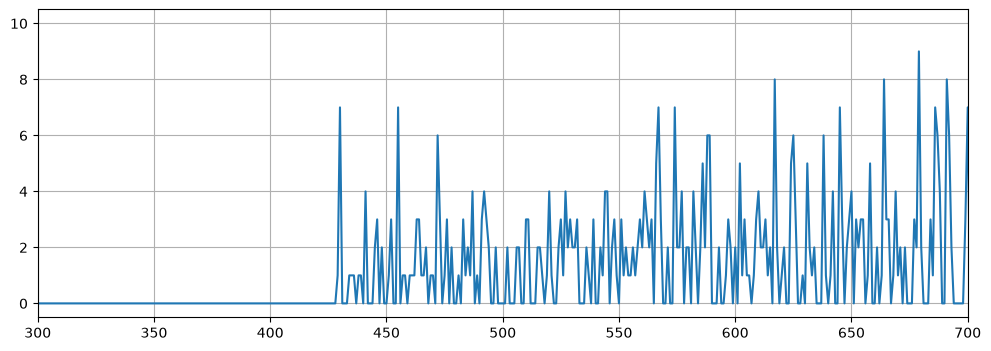

In [10]:
item1 = sales_long[sales_long['item_id'] == 'HOBBIES_1_006'].reset_index(drop = True)

plt.figure(figsize = (12, 4))
plt.plot(item1.index, item1['sales'])
plt.grid()
plt.xlim(300, 700)

---
## calendar Dataset

In [11]:
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


In [12]:
print("start date: ", calendar['date'].min())
print("end date: ", calendar['date'].max())
print('event name: ', calendar['event_name_1'].unique())
print('event type: ', calendar['event_type_1'].unique())

calendar[~calendar['event_name_1'].isnull()].sample(5)

start date:  2011-01-29
end date:  2016-06-19
event name:  <ArrowStringArray>
[                  nan,           'SuperBowl',       'ValentinesDay',
       'PresidentsDay',           'LentStart',           'LentWeek2',
       'StPatricksDay',           'Purim End',      'OrthodoxEaster',
          'Pesach End',       'Cinco De Mayo',        'Mother's day',
         'MemorialDay',      'NBAFinalsStart',        'NBAFinalsEnd',
        'Father's day',     'IndependenceDay',      'Ramadan starts',
         'Eid al-Fitr',            'LaborDay',         'ColumbusDay',
           'Halloween',           'EidAlAdha',         'VeteransDay',
        'Thanksgiving',           'Christmas',        'Chanukah End',
             'NewYear',   'OrthodoxChristmas', 'MartinLutherKingDay',
              'Easter']
Length: 31, dtype: str
event type:  <ArrowStringArray>
[nan, 'Sporting', 'Cultural', 'National', 'Religious']
Length: 5, dtype: str


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
1006,2013-10-31,11340,Thursday,6,10,2013,d_1007,Halloween,Cultural,NaN,NaN,0,0,0
121,2011-05-30,11118,Monday,3,5,2011,d_122,MemorialDay,National,NaN,NaN,0,0,0
134,2011-06-12,11120,Sunday,2,6,2011,d_135,NBAFinalsEnd,Sporting,NaN,NaN,0,1,1
746,2013-02-13,11303,Wednesday,5,2,2013,d_747,LentStart,Religious,NaN,NaN,0,1,0
1919,2016-05-01,11614,Sunday,2,5,2016,d_1920,OrthodoxEaster,Religious,NaN,NaN,1,1,0


In [13]:
calendar_features = calendar[[ "date", "d", "wm_yr_wk", "event_name_1", "event_type_1", 
                              "event_name_2", "event_type_2", "snap_CA",]].copy()

calendar_features.sample(5)

,date,d,wm_yr_wk,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA
29,2011-02-27,d_30,11105,NaN,NaN,NaN,NaN,0
1572,2015-05-20,d_1573,11516,NaN,NaN,NaN,NaN,0
1949,2016-05-31,d_1950,11618,NaN,NaN,NaN,NaN,0
765,2013-03-04,d_766,11306,NaN,NaN,NaN,NaN,1
693,2012-12-22,d_694,11248,NaN,NaN,NaN,NaN,0


---

## sell prices dataset

In [14]:
sell_prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [15]:
print(sell_prices.shape)
print(sell_prices['wm_yr_wk'].nunique())

(6841121, 4)
282


In [16]:
# Filter prices for CA_1
prices_ca1 = sell_prices[sell_prices["store_id"] == "CA_1"].copy()
prices_ca1.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


---
## Join dataset

In [17]:
# Join calendar information to daily sales
sales_long = sales_long.merge(calendar_features, on = 'd', how = 'left', validate="many_to_one")

sales_long = sales_long.merge(prices_ca1, on = ["store_id", "item_id", "wm_yr_wk"], 
                              how = 'left', validate = "many_to_one")

In [18]:
sales_long[sales_long['sales']!=0].head()

,id,item_id,dept_id,cat_id,store_id,d,sales,date,wm_yr_wk,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,sell_price
7,HOBBIES_1_008_CA_1_validation,HOBBIES_1_008,HOBBIES_1,HOBBIES,CA_1,d_1,12,2011-01-29,11101,NaN,NaN,NaN,NaN,0,0.46
8,HOBBIES_1_009_CA_1_validation,HOBBIES_1_009,HOBBIES_1,HOBBIES,CA_1,d_1,2,2011-01-29,11101,NaN,NaN,NaN,NaN,0,1.56
14,HOBBIES_1_015_CA_1_validation,HOBBIES_1_015,HOBBIES_1,HOBBIES,CA_1,d_1,4,2011-01-29,11101,NaN,NaN,NaN,NaN,0,0.70
15,HOBBIES_1_016_CA_1_validation,HOBBIES_1_016,HOBBIES_1,HOBBIES,CA_1,d_1,5,2011-01-29,11101,NaN,NaN,NaN,NaN,0,0.70
21,HOBBIES_1_022_CA_1_validation,HOBBIES_1_022,HOBBIES_1,HOBBIES,CA_1,d_1,2,2011-01-29,11101,NaN,NaN,NaN,NaN,0,6.86


In [19]:
# Convert date to datetime
sales_long["date"] = pd.to_datetime(sales_long["date"])

# Sort chronologically within each product
sales_long = sales_long.sort_values(
    ["item_id", "date"]
).reset_index(drop=True)

# Verify
print(sales_long["date"].dtype)
print(sales_long[["item_id", "date", "sales", "sell_price"]].head())

datetime64[us]
       item_id       date  sales  sell_price
0  FOODS_1_001 2011-01-29      3         2.0
1  FOODS_1_001 2011-01-30      0         2.0
2  FOODS_1_001 2011-01-31      0         2.0
3  FOODS_1_001 2011-02-01      1         2.0
4  FOODS_1_001 2011-02-02      4         2.0


In [20]:
# Proportion of missing prices
print(sales_long["sell_price"].isna().mean())

# Missing prices by product
print(
    sales_long.groupby("item_id")["sell_price"]
    .apply(lambda x: x.isna().mean())
    .describe()
)

# Sales on rows with missing prices
missing_price = sales_long["sell_price"].isna()

print("Rows with missing price:", missing_price.sum())
print("Sales on missing-price rows:", sales_long.loc[missing_price, "sales"].sum())
print("Nonzero sales with missing price:",
      ((sales_long["sales"] > 0) & missing_price).sum())

0.19370700239013006
count    3049.000000
mean        0.193707
std         0.241290
min         0.000000
25%         0.000000
50%         0.032933
75%         0.391532
max         0.962363
Name: sell_price, dtype: float64
Rows with missing price: 1129842
Sales on missing-price rows: 0
Nonzero sales with missing price: 0


In [21]:
output_path = ROOT / "data" / "processed"
output_path.mkdir(parents=True, exist_ok=True)

sales_long.to_parquet(output_path / "ca1_sales.parquet", index=False)